In [1]:
# importing necessary modules that will be used in our script
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

I0000 00:00:1791786671.209922    4905 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791786672.258921    4905 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791786675.227057    4905 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANEL = 3
EPOCHS = 50

In [3]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../training_dataset", # directory of your source dataset
    shuffle=True, #randomly shuffling images
    image_size = (IMAGE_SIZE, IMAGE_SIZE), # resize all images to have same dimensions
    batch_size = BATCH_SIZE # load 32 image for each batch
)

Found 2152 files belonging to 3 classes.


E0000 00:00:1791786678.466513    4905 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [5]:
len(dataset) # it runned 68 batches nd for every batch it is loading 32 image so 68 * 32 is 2176

68

In [6]:
for batch_image, label_batch in dataset.take(1):
    print(batch_image.shape)
    print(label_batch.numpy())
    # 0 is Potato___Early_blight, 1 is Potato___Late_blight and 2 is Potato___healthy just like array of our class_names

(32, 256, 256, 3)
[2 1 0 1 2 0 0 1 0 1 0 0 1 1 0 0 1 1 0 0 0 1 1 0 0 0 0 2 1 1 2 2]


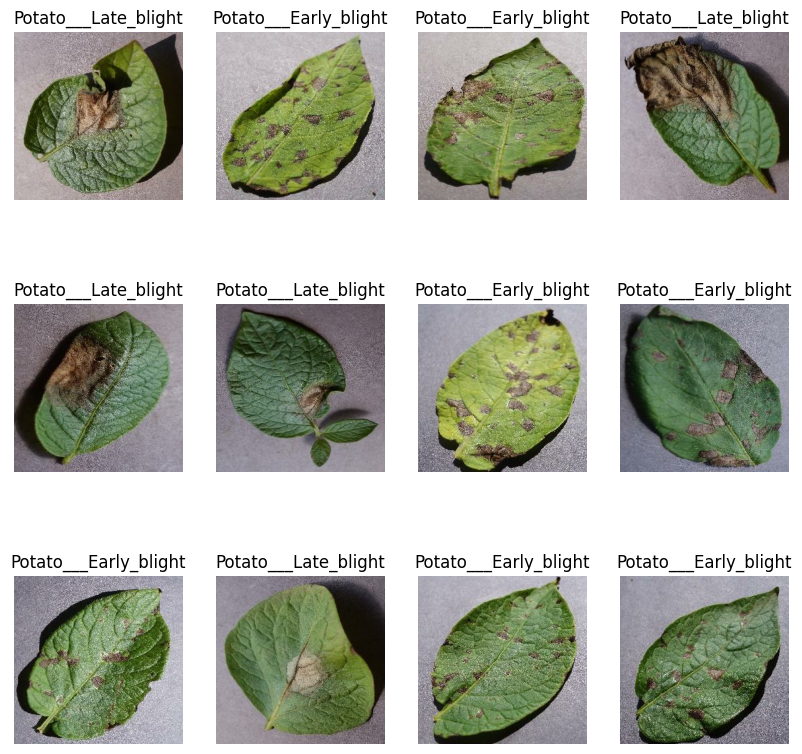

In [9]:
plt.figure(figsize=(10, 10))
for batch_image, label_batch in dataset.take(1):
    for i in range(12):
            #  i + 1 means space to be added btn the images, and 3 means three rows , 4 columns
            ax = plt.subplot(3, 4, i + 1)
            plt.axis("off") # hidding x axis numbers an y-axis numbers
            plt.imshow(batch_image[i].numpy().astype("uint8"))
            plt.title(class_names[label_batch[i]])
            # print(batch_image[0].numpy())

In [8]:
# BIG OVERVIEW
80% ==> training
20% ==> 10% validation, 10% test

SyntaxError: invalid syntax (792919850.py, line 2)

In [10]:
training_size = 0.8
len(dataset)*training_size

54.400000000000006

In [11]:
training_ds = dataset.take(54)

In [12]:
test_ds = dataset.skip(54)
len(test_ds)

14

In [13]:
validation = 0.1
len(dataset)*validation

6.800000000000001

In [14]:
validation_ds = test_ds.take(6)

In [15]:
test_ds = test_ds.skip(6)

In [19]:
def get_dataset_partition_tf(ds, train_split=0.8, validation_split=0.1, test_split=0.1, shuffle=True, shuffle_size=1000):
    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size)
    training_size = int(ds_size * train_split)
    validation_size = int(ds_size * validation_split)
    training_ds = ds.take(training_size)
    
    test_ds = ds.skip(training_size).take(validation_size)
    validation_ds = ds.skip(training_size).skip(validation_size)

    return training_ds, test_ds, validation_ds

In [20]:
training_ds, test_ds, validation_ds = get_dataset_partition_tf(dataset)

In [21]:
len(training_ds)

54

In [22]:
# better approach if you're building a big project with small RAM
training_ds = training_ds.prefetch(1)
test_ds = test_ds.prefetch(1)
validation_ds = validation_ds.prefetch(1)

In [23]:
# next step is image preprocessing (scale, resize)
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0/255)
])

In [24]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

In [ ]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE)
model = tf.keras.Sequential(
    resize_and_rescale,
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation = "relu", input_shape = input_shape),
    layers.MaxPoOling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation = "relu"),
    layers.Dense(3, activation = "softmax")
)